# 02 — Exploratory data analysis
PRD §8: the ten required plots and the six questions. Event-level plots use the cleaned keystrokes; window-level plots use 30-second windows (notebook 03).

In [1]:
import sys, json
sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src import config, cleaning, features, baseline
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 40)
sns.set_theme(style='whitegrid')
config.FIG_DIR.mkdir(parents=True, exist_ok=True)
def save(name): plt.tight_layout(); plt.savefig(config.FIG_DIR / f'{name}.png', dpi=130)

In [2]:
ev = pd.read_csv(config.CLEAN_PATH, parse_dates=['timestamp'])
win = features.build_windows(ev)
print(ev.shape, win.shape)

(100000, 14) (1000, 24)


### 1. Dwell-time distribution

skew: 0.97


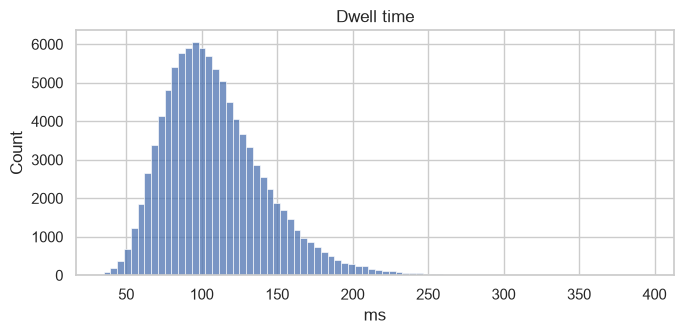

In [3]:
fig, ax = plt.subplots(figsize=(7,3.5)); sns.histplot(ev.dwell_time_ms, bins=80, ax=ax); ax.set(title='Dwell time', xlabel='ms'); save('eda_01_dwell')
print('skew:', round(ev.dwell_time_ms.skew(), 2))

### 2. Flight-time distribution (log scale: pauses form a second mode)

skew: 9.42 | share > pause threshold: 0.0107


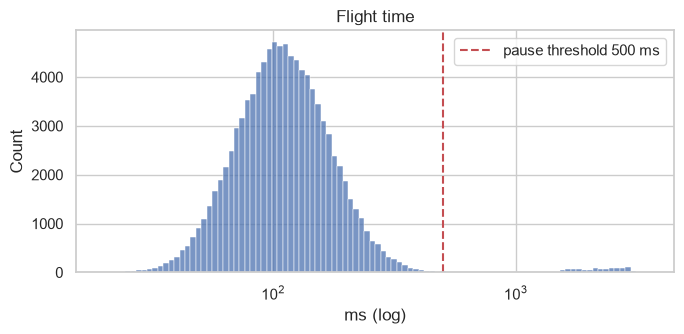

In [4]:
fig, ax = plt.subplots(figsize=(7,3.5)); sns.histplot(ev.flight_time_ms, bins=100, log_scale=True, ax=ax)
ax.axvline(config.PAUSE_MS, c='r', ls='--', label=f'pause threshold {config.PAUSE_MS} ms'); ax.legend(); ax.set(title='Flight time', xlabel='ms (log)'); save('eda_02_flight')
print('skew:', round(ev.flight_time_ms.skew(), 2), '| share > pause threshold:', round(ev.is_pause.mean(), 4))

### 3. Typing-speed distribution (per window)

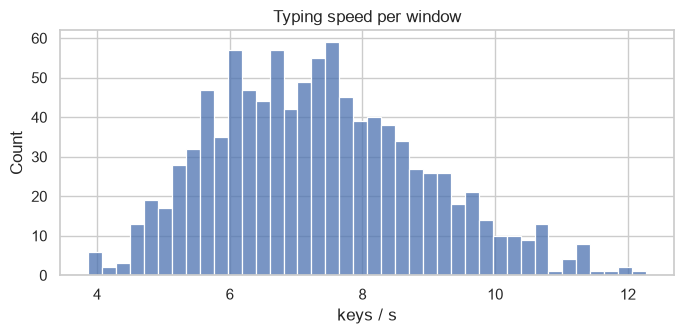

In [5]:
fig, ax = plt.subplots(figsize=(7,3.5)); sns.histplot(win.typing_speed, bins=40, ax=ax); ax.set(title='Typing speed per window', xlabel='keys / s'); save('eda_03_speed')

### 4. Pause-duration distribution

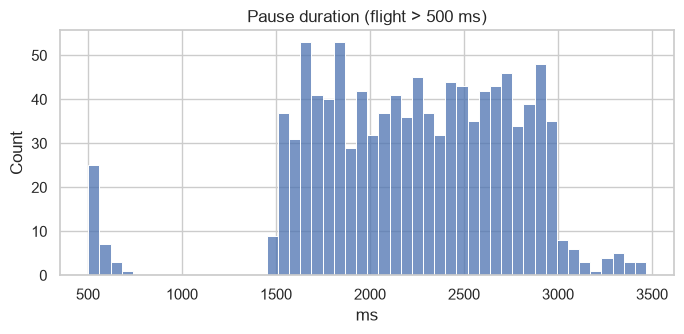

In [6]:
fig, ax = plt.subplots(figsize=(7,3.5)); sns.histplot(ev.loc[ev.is_pause, 'flight_time_ms'], bins=50, ax=ax); ax.set(title='Pause duration (flight > 500 ms)', xlabel='ms'); save('eda_04_pause')

### 5. Correction-rate distribution (per window)

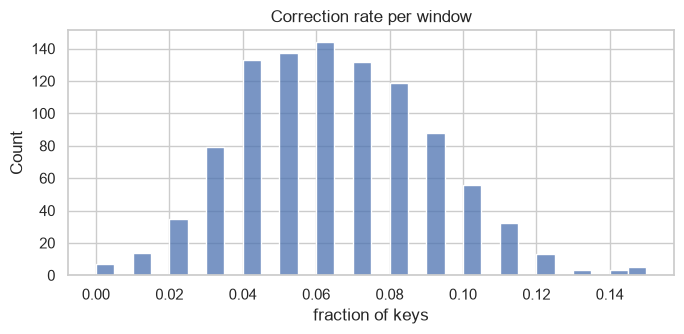

In [7]:
fig, ax = plt.subplots(figsize=(7,3.5)); sns.histplot(win.correction_rate, bins=30, ax=ax); ax.set(title='Correction rate per window', xlabel='fraction of keys'); save('eda_05_correction')

### 6. Mood-state distribution: events vs window majority labels

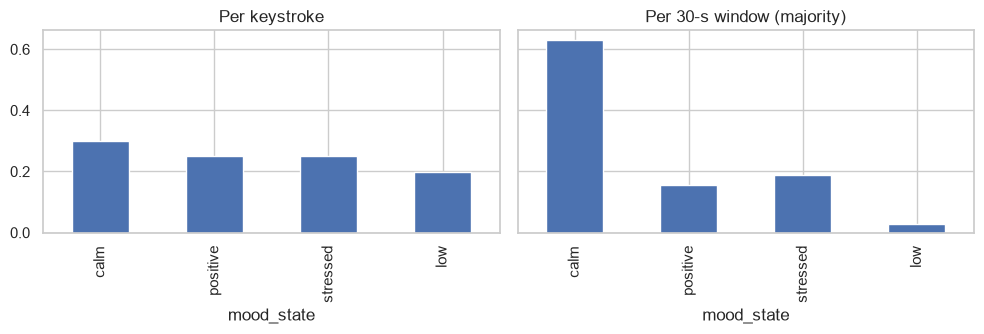

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10,3.5), sharey=True)
ev.mood_state.value_counts(normalize=True).reindex(config.MOODS).plot.bar(ax=axes[0], title='Per keystroke')
win.mood_state.value_counts(normalize=True).reindex(config.MOODS).plot.bar(ax=axes[1], title='Per 30-s window (majority)')
save('eda_06_mood')

### 7. User-level typing-speed comparison

between-user CV of mean feature:
typing_speed        0.151
mean_dwell          0.084
std_dwell           0.085
mean_flight         0.175
std_flight          0.171
mean_pause          0.192
pause_count         0.235
long_pause_count    0.270
correction_rate     0.201
dtype: float64


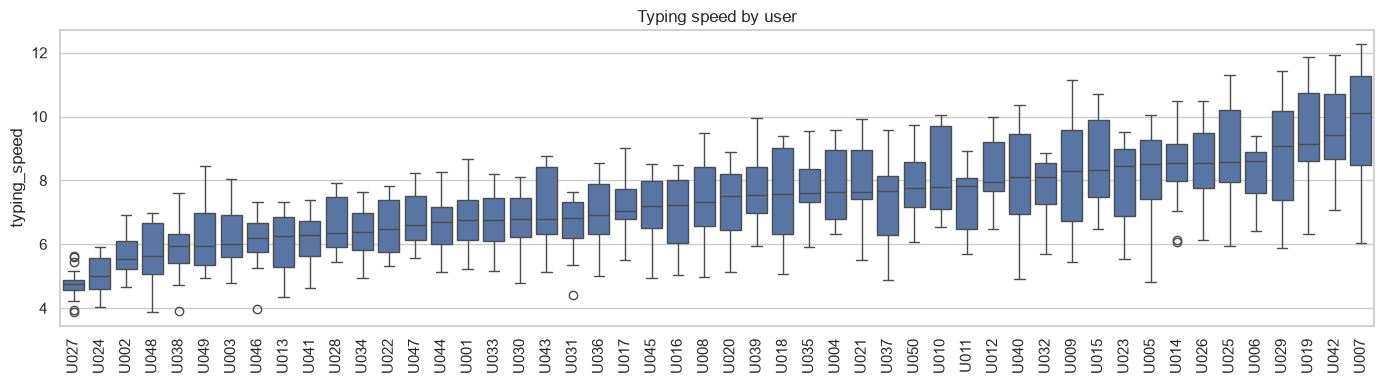

In [9]:
order = win.groupby('user_id').typing_speed.median().sort_values().index
fig, ax = plt.subplots(figsize=(14,4)); sns.boxplot(win, x='user_id', y='typing_speed', order=order, ax=ax)
ax.tick_params(axis='x', rotation=90); ax.set(title='Typing speed by user', xlabel=''); save('eda_07_users')
u = win.groupby('user_id')[config.CORE_FEATURES].mean()
print('between-user CV of mean feature:'); print((u.std()/u.mean()).round(3))

### 8. Correlation heatmap (window features and labels)

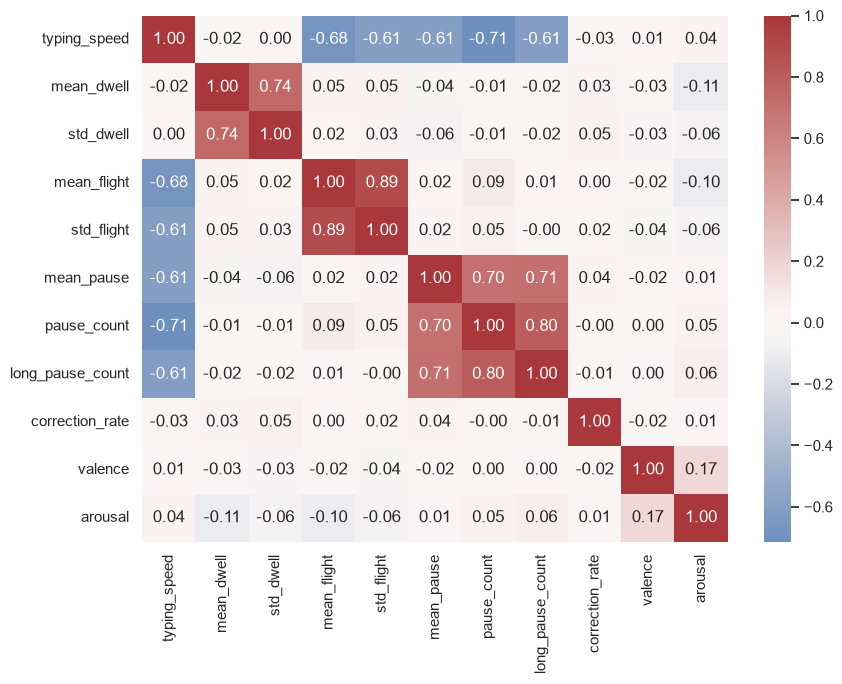

In [10]:
fig, ax = plt.subplots(figsize=(9,7)); sns.heatmap(win[config.CORE_FEATURES + ['valence','arousal']].corr(), annot=True, fmt='.2f', cmap='vlag', center=0, ax=ax); save('eda_08_corr')

### 9. Feature distributions by mood
Shown at keystroke level (where the label is exact) and at window level (where the label is a majority vote).

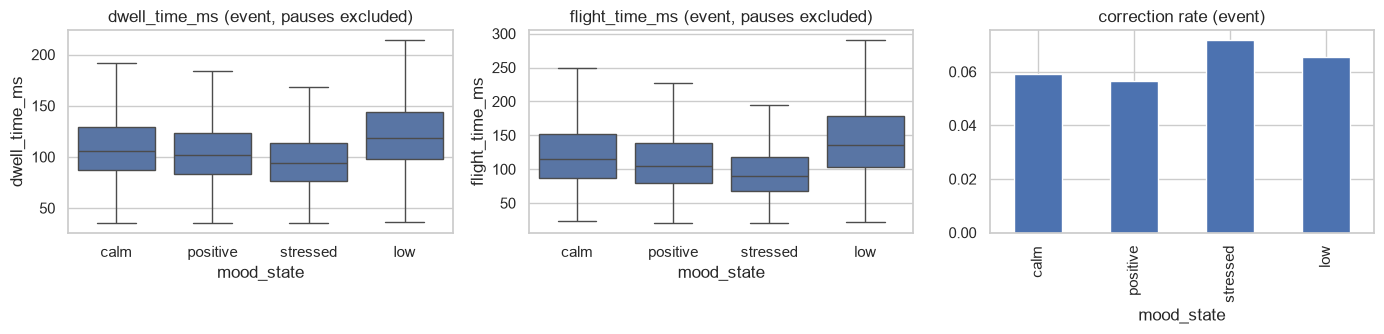

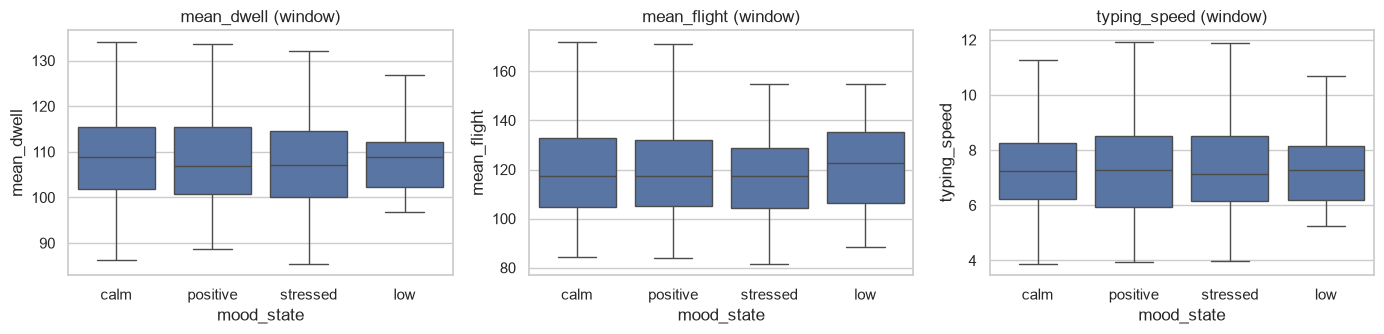

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14,3.5))
for ax, col in zip(axes, ['dwell_time_ms', 'flight_time_ms', 'is_correction']):
    if col == 'is_correction':
        ev.groupby('mood_state')[col].mean().reindex(config.MOODS).plot.bar(ax=ax, title='correction rate (event)')
    else:
        sns.boxplot(ev[~ev.is_pause], x='mood_state', y=col, order=config.MOODS, showfliers=False, ax=ax); ax.set_title(f'{col} (event, pauses excluded)')
save('eda_09a_by_mood_events')
fig, axes = plt.subplots(1, 3, figsize=(14,3.5))
for ax, col in zip(axes, ['mean_dwell', 'mean_flight', 'typing_speed']):
    sns.boxplot(win, x='mood_state', y=col, order=config.MOODS, showfliers=False, ax=ax); ax.set_title(f'{col} (window)')
save('eda_09b_by_mood_windows')

In [12]:
effect = ev[~ev.is_pause].groupby('mood_state')[['dwell_time_ms','flight_time_ms','is_correction']].mean().reindex(config.MOODS)
print('event-level means by mood'); print(effect.round(3))
print('\nwindow-level means by majority mood'); print(win.groupby('mood_state')[config.CORE_FEATURES].mean().reindex(config.MOODS).round(3))

event-level means by mood
            dwell_time_ms  flight_time_ms  is_correction
mood_state                                              
calm              110.503         125.376          0.059
positive          105.898         114.456          0.056
stressed           97.360          97.920          0.072
low               123.548         146.925          0.066

window-level means by majority mood
            typing_speed  mean_dwell  std_dwell  mean_flight  std_flight  mean_pause  pause_count  long_pause_count  correction_rate
mood_state                                                                                                                          
calm               7.302     108.939     32.014      120.742      50.200    1503.621        1.073             0.678            0.062
positive           7.347     108.294     32.356      120.229      49.734    1409.016        1.103             0.737            0.059
stressed           7.419     108.123     32.471      117.996   

### 10. Valence vs arousal

valence-arousal correlation (events): 0.208
valence-arousal correlation (windows): 0.173


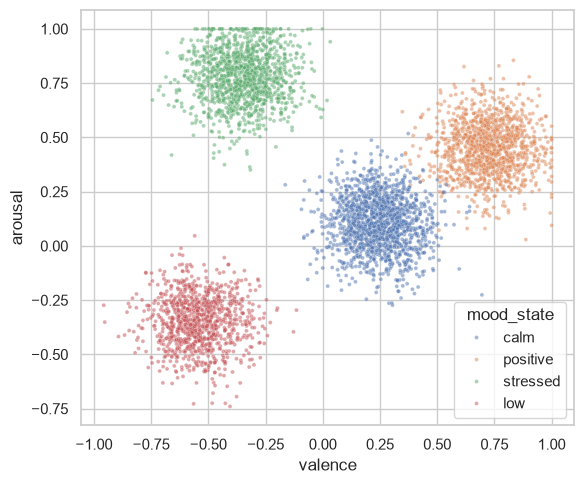

In [13]:
s = ev.sample(5000, random_state=0)
fig, ax = plt.subplots(figsize=(6,5)); sns.scatterplot(s, x='valence', y='arousal', hue='mood_state', hue_order=config.MOODS, s=8, alpha=.5, ax=ax); save('eda_10_va')
print('valence-arousal correlation (events):', round(ev.valence.corr(ev.arousal), 3))
print('valence-arousal correlation (windows):', round(win.valence.corr(win.arousal), 3))

## Answers to the PRD §8 questions
**Are timing distributions skewed?** Yes. Dwell is mildly right-skewed (skew ≈ 1.0). Flight is heavily right-skewed (skew ≈ 9.4) because of a second mode of pauses above 500 ms (about 1% of keystrokes), which is why pauses get their own features and are excluded from `mean_flight`.

**Do users have different baselines?** Yes. Between-user coefficient of variation is 15% for typing speed, 17% for flight time and 8% for dwell time (plot 7). That is the motivation for personal baselines.

**Which features vary most between states?** Per keystroke: flight time (stressed ≈ 98 ms vs low ≈ 147 ms) and dwell time (stressed ≈ 97 ms vs low ≈ 124 ms). Per 30-second window those gaps nearly vanish (window mean flight 118–121 ms for every mood) because each window mixes all four moods.

**Are valence and arousal correlated?** Weakly: r ≈ 0.21 per keystroke, 0.17 per window.

**Are there outliers?** 100 negative dwell values (invalid, fixed in 01) and long flights up to ~3.5 s (kept as pauses).

**Does correction behaviour differ by state?** Slightly: stressed has the highest correction rate (≈ 7.2% of keys vs ≈ 5.6–6.6% for the others).

**Key EDA finding:** the dataset contains a real per-keystroke mood signal, but mood is re-drawn almost every keystroke (average run 1.3 keys), so 30-second windows average it away. This predicts the weak window-level results in notebook 04.